In [1]:
import os
os.chdir('D:/tmp_workplace/dynamic_structure/250619/RIC_data_analysis/all_analysis/v4/well_folded_structure_finding')
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.cluster.hierarchy import leaves_list
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy import stats

In [2]:
def load_fasta(fasta_path, select_id=None):
    '''
    fasta_dict      {id : seq list}
    '''
    #fasta_path:in file
    #select_id:id list
    fasta_dict = {}
    fasta = open(fasta_path,'r')
    for line in fasta:
        if line.startswith(">"):
            seqid = line.strip().split()[0][1:]
            fasta_dict[seqid] = ''
        else:
            fasta_dict[seqid] += line.strip()
    fasta.close()
    if select_id:
        select_dict = {}
        for select in select_id:
            test = fasta_dict.get(select)
            if test:
                select_dict[select] = list(test)
            else:
                print("seq is not in fasta",select)
        if  (len(select_dict) != 0):
            return select_dict
        else:
            print('all select not in fasta')
    else:
        return fasta_dict
    
def raw_mafft_index_map(raw_seqlist,mafft_seqlist):
    index_map = {}
    gap = 0
    for i,seq in enumerate(raw_seqlist):
        while raw_seqlist[i] != mafft_seqlist[i+gap]:
            gap += 1
        index_map[i] = i + gap
    return index_map

def get_shannon(matrix, n, res):
    (x,y) = np.diag_indices_from(matrix)
    shannon_ma = np.zeros_like(matrix)
    #shannon_ma[x,y] = matrix[x,y].copy()
    shan_out = []
    true_shan_out = []
    x = np.delete(x, 0)
    y = np.delete(y, -1)
    for i in np.arange(n-1):
        shannon_ma[x,y] = matrix[x,y].copy()
        shannon_ma[y,x] = matrix[y,x].copy()
        x = np.delete(x, 0)
        y = np.delete(y, -1)
    shannon_sum = shannon_ma.sum(axis=1)
    p_ma = shannon_ma / shannon_sum
    p_ma[np.isnan(p_ma)] = 0
    for i,arrs in enumerate(p_ma.T):
        p = arrs[arrs>0]
        shan = np.sum(p*np.log2(p)) * -1
        shan_out.append(shan)
        for iters in range(res):
            true_shan_out.append(shan)       
    return np.array(shan_out), np.array(true_shan_out)

def get_matrix_npz(M1,M2):
    '''
    use rri-matrix dump result to creat matrix 
    '''
    S1 = sparse.coo_matrix((M1['value'],(np.asarray(M1['S'], dtype= 'i4'),np.asarray(M1['E'], dtype= 'i4')))).toarray()
    S2 = sparse.coo_matrix((M2['value'],(np.asarray(M2['E'], dtype= 'i4'),np.asarray(M2['S'], dtype= 'i4')))).toarray()
    matrix = np.zeros((max(S1.shape),max(S1.shape)))
    matrix[np.nonzero(S1)] = S1[np.nonzero(S1)]
    matrix[np.nonzero(S2)] = S2[np.nonzero(S2)]
    return matrix

def extract_matrix(file_name,res):
    data = np.loadtxt(file_name, usecols=[0,1,2], dtype=[('S','<i4'),('E','<i4'),('value','<f8')])
    data['S'] = data['S'] / res
    data['E'] = data['E'] / res
    data['value'][data['value'] < 0] = 0
    data['value'][np.isnan(data['value'])] = 0
    matrix = get_matrix_npz(data,data)
    return matrix

def load_pair_bedpe(in_bedpe):
    pairs = set()
    ib = open(in_bedpe, "r")
    for line in ib:
        line = line.strip().split()
        if 'chrom1' in line:
            continue
        else:
            left = int(line[1])
            right = int(line[4])
            if left > right:
                continue
            pairs.add((left,right))
    ib.close()
    return pairs

def pairs_to_index_array(pairs,length):
    tmp = np.zeros(length)
    for pair in pairs:
        left = int(pair[0])
        right = int(pair[1])
        tmp[left] = 1
        tmp[right] = 1
    return tmp

def get_connection(ma, pairs, res, length):
    value_dict = {}
    structure_value = []
    for pair in pairs:
        value = ma[int((int(pair[0]))//res),int((int(pair[1]))/res)]
        value = np.log(value / res**2 +1)
        value_dict[int(pair[0])] = value
        value_dict[int(pair[1])] = value
        structure_value.append(value)
        structure_value.append(value)
    locs = []
    values = []
    for i in range(length):
        locs.append(i)
        if value_dict.get(i):
            values.append(value_dict.get(i))
        else:
            values.append(0)
    return locs, values, structure_value

def find_continuous_sequences(a):
    if not a:
        return []  # 如果列表为空，返回空列表

    # 去重并排序
    sorted_a = sorted(set(a))
    result = []
    current_sequence = [sorted_a[0]]

    for num in sorted_a[1:]:
        if num == current_sequence[-1] + 1:
            current_sequence.append(num)
        else:
            # 当前序列结束，记录结果
            if len(current_sequence) >= 1:  # 至少有一个元素
                result.append((current_sequence[0], current_sequence[-1]))
            current_sequence = [num]  # 开始新的序列

    # 处理最后一组序列
    if len(current_sequence) >= 1:
        result.append((current_sequence[0], current_sequence[-1]))

    return result

def merge_interval(interval_list,output_file):
    # 初始化变量
    current_intervals = interval_list.copy()
    
    # 执行 20 次迭代合并
    for _ in range(20):
        merged_intervals = []
        processed = [False] * len(current_intervals)
        
        # 合并相邻的区间
        i = 0
        while i < len(current_intervals):
            if processed[i]:
                i += 1
                continue
            
            current = current_intervals[i]
            next_index = i + 1
            
            # 尝试合并当前区间和下一个区间
            while next_index < len(current_intervals) and not processed[next_index]:
                next_interval = current_intervals[next_index]
                if next_interval[0] - current[1] < 10:
                    current = (current[0], next_interval[1])
                    processed[next_index] = True
                else:
                    break
                next_index += 1
            
            merged_intervals.append(current)
            i += 1
        
        # 更新当前区间列表
        current_intervals = merged_intervals

    final_intervals = [(s,e) for s,e in current_intervals if e-s+1 >= 20]
    
    # 筛选长度大于等于 40 的区间并写入输出文件
    with open(output_file, "w") as f:
        f.write('chrom1'+"\t"+'start1'+'\t'+'end1'+'\t'+'chrom2'+"\t"+'start2'+'\t'+'end2'+'\n')
        for interval in final_intervals:
            f.write('HS1'+"\t"+str(interval[0])+"\t"+str(interval[1])+"\t"+"HS1"+"\t"+str(interval[0])+"\t"+str(interval[1])+"\n")

    return final_intervals

def load_intervals(in_file):
    intervals = []
    with open(in_file, "r")as f:
        for line in f:
            if 'chrom1' in line:
                continue
            else:
                line = line.strip().split()
                intervals.append((int(line[1]),int(line[2])))
    return intervals

def renew_intervals_index(intervals, index_map):
    new_intervals = []
    for interval in intervals:
        new_start = index_map.get(interval[0])
        new_end = index_map.get(interval[1])
        new_intervals.append((new_start, new_end))
    return new_intervals

def make_intervals_set(intervals):
    intervals_set = set()
    for interval in intervals:
        for i in range(interval[0],interval[1]+1):
            intervals_set.add(i)
    return intervals_set

def load_value(in_file):
    values = []
    with open(in_file,'r')as f:
        for line in f:
            values.append(float(line.strip()))
    return values

def select_region_shannon(shannon, intervals, length):
    locs = set(range(length))
    intervals_set = make_intervals_set(intervals)
    not_well_locs = locs - intervals_set
    well_shannon = [shannon[i] for i in intervals_set]
    not_well_shannon = [shannon[i] for i in not_well_locs]
    return well_shannon,not_well_shannon

def split_structure_bedpe(structure_pairs,length):
    st = np.zeros(length)
    for pair in structure_pairs:
        st[pair[0]] = 1
        st[pair[1]] = -1
    st_type = []
    dict_st = {}
    sum_score = 0
    count = 1
    tem_score = 0 
    gap_s = 0
    bound = [0]
    for i,x in enumerate(st):
        sum_score += x
        if tem_score == 0 and sum_score == 0:
             st_type.append( 'gap_' + str(count) )
            
        elif tem_score == 0 and sum_score != 0:
             st_s = i
             st_type.append( 'stem-loop_' + str(count) )
             gap_e = i - 1
             if gap_s <= gap_e:
                dict_st['gap_' + str(count)] = (gap_s, gap_e)
            
        elif tem_score != 0 and sum_score != 0:
             st_type.append( 'stem-loop_' + str(count) )
            
        elif tem_score != 0 and sum_score == 0:    
             st_type.append( 'stem-loop_' + str(count) )
             st_e = i
             gap_s = i + 1
             dict_st['stem-loop_' + str(count)] = (st_s,st_e)  
             count += 1
             #dict_st['gap_' + str(count)] = (gap_s, len(st) - 1) 
             bound.append(i)
        
            # if tem_score == 0:
            #     st_s = i
            #     gap_e = i - 1
            #     dict_st['gap_' + str(count)] = (gap_s, gap_e)    
        # elif sum_score > 0 :
        #    st_type.append( 'stem-loop_' + str(count) )
           
        tem_score = sum_score
    bound.append(i)
    return st_type, dict_st, bound

def find_well_folded_structure(st_type, shannon, connection):
    shannon_mean = np.mean(shannon)
    connection_mean = np.mean(connection)
    well_folded_st = {}
    not_well_folded_st = {}
    for st in st_type:
        if 'gap' in st:
            continue
        else:
            st_s = st_type[st][0]
            st_e = st_type[st][1]
            st_shannon = np.mean(shannon[st_s:st_e+1])
            st_connection = np.mean(connection[st_s:st_e+1])
            if st_shannon < shannon_mean and st_connection > connection_mean:
                well_folded_st[st] = st_type[st]
            else:
                not_well_folded_st[st] = st_type[st]
    return well_folded_st,not_well_folded_st

def calculate_structure_shannon_connection(st_type,shannon,connection):
    total_dict = {
        'shannon':[],
        'connection':[],
        'length':[]
    }
    for st in st_type:
        st_s = st_type[st][0]
        st_e = st_type[st][1]
        total_dict['shannon'].append(np.mean(shannon[st_s:st_e+1]))
        total_dict['connection'].append(np.mean(connection[st_s:st_e+1]))
        total_dict['length'].append(st_e - st_s + 1)
    return total_dict

def return_well_folded_list(wf_st_type,shannon,connection):
    wf_shannon = []
    wf_connection = []
    wf_length = []
    for st in wf_st_type:
        st_s = wf_st_type[st][0]
        st_e = wf_st_type[st][1]
        wf_shannon.append(np.mean(shannon[st_s:st_e+1]))
        wf_connection.append(np.mean(connection[st_s:st_e+1]))
        wf_length.append(st_e - st_s + 1)
    return wf_shannon,wf_connection,wf_length

def save_clusters(labels,structure_locs,prefix):
    out_file = prefix + "_structure_clusters.info"
    with open(out_file,'w')as f:
        for index,cluter_num in enumerate(labels):
            f.write(str(cluter_num)+"\t"+str(structure_locs[index][0])+"\t"+str(structure_locs[index][1])+"\n")

def save_well_folded_clusters(well_folded_labels,labels,structure_locs,prefix):
    out_file = prefix + "_well_folded_structure.info"
    labels = np.array(labels)
    with open(out_file,'w')as f:
        for cluter_num in well_folded_labels:
            indexs = np.where(labels == cluter_num)[0]
            for index in list(indexs):
                f.write(str(structure_locs[index][0])+"\t"+str(structure_locs[index][1])+"\n")

def save_two_type_well_folded_clusters(well_folded_labels,labels,structure_locs,prefix,structure_e,structure_cs,med_e,med_cs):
    certain_file = prefix + "_well_folded_structure_certain.info"
    vague_file = prefix + "_well_folded_structure_vague.info"
    labels = np.array(labels)
    cf = open(certain_file,'w')
    vf = open(vague_file,'w')

    for cluter_num in well_folded_labels:
        indexs = np.where(labels == cluter_num)[0]
        for index in list(indexs):
            tmp_e = structure_e[index]
            tmp_cs = structure_cs[index]
            if (tmp_e <= med_e) and (tmp_cs >= med_cs):
                cf.write(str(structure_locs[index][0])+"\t"+str(structure_locs[index][1])+"\n")
            else:
                vf.write(str(structure_locs[index][0])+"\t"+str(structure_locs[index][1])+"\n")
    cf.close()
    vf.close()

def calculate_stem_shannon_connection(st_type,shannon_list,connection_matrix,prefix,structure_pairs):
    #print(len(shannon_list),len(connection_list),len(binary_structure))
    shannon = []
    connection = []
    length = []
    structure_locs = []
    for st in st_type:
        tmp_shannon = []
        tmp_connection = []

        if 'gap' in st:
            continue
        st_s = st_type[st][0]
        st_e = st_type[st][1]
        
        for pair in structure_pairs:
            left = pair[0]
            right = pair[1]
            if (left >= st_s) and (right >= st_s) and (left <= st_e) and (right <= st_e):
                tmp_shannon.append(shannon_list[left]*shannon_list[right])
                tmp_connection.append(connection_matrix[int(left/10),int(right/10)])

        shannon.append(np.mean(tmp_shannon))
        connection.append(np.mean(tmp_connection))
        length.append(st_e - st_s + 1)
        structure_locs.append((str(st_s),str(st_e)))
    out_file = prefix + '_structure.info'
    with open(out_file,'w')as f:
        for i,j in structure_locs:
            f.write(i+"\t"+j+"\n")
    return shannon,connection,length,structure_locs

def calculate_structure_average_length_shannon_connection(st_type,wf_st_type,nwf_st_type,shannon_list,connection_list,save=False,out_file=None):
    gap_count = 0
    gap_shannon = []
    gap_connection = []
    gap_length = []
    for st in st_type:
        if 'gap' in st:
            gap_count += 1
            st_s = st_type[st][0]
            st_e = st_type[st][1]
            #print((st_s,st_e))
            gap_shannon.append(np.mean(shannon_list[st_s:st_e+1]))
            gap_connection.append(np.mean(connection_list[st_s:st_e+1]))
            gap_length.append(st_e - st_s + 1)
    gap_dict = {
        'shannon':np.mean(gap_shannon),
        'connection':np.mean(gap_connection),
        'length':np.mean(gap_length),
        'count':gap_count
    }

    wf_count = 0
    wf_shannon = []
    wf_connection = []
    wf_length = []
    for st in wf_st_type:
        wf_count += 1
        st_s = wf_st_type[st][0]
        st_e = wf_st_type[st][1]
        wf_shannon.append(np.mean(shannon_list[st_s:st_e+1]))
        wf_connection.append(np.mean(connection_list[st_s:st_e+1]))
        wf_length.append(st_e - st_s + 1)
    wf_dict = {
        'shannon':np.mean(wf_shannon),
        'connection':np.mean(wf_connection),
        'length':np.mean(wf_length),
        'count':wf_count
    }

    nwf_count = 0
    nwf_shannon = []
    nwf_connection = []
    nwf_length = []
    for st in nwf_st_type:
        nwf_count += 1
        st_s = nwf_st_type[st][0]
        st_e = nwf_st_type[st][1]
        nwf_shannon.append(np.mean(shannon_list[st_s:st_e+1]))
        nwf_connection.append(np.mean(connection_list[st_s:st_e+1]))
        nwf_length.append(st_e - st_s + 1)
    nwf_dict = {
        'shannon':np.mean(nwf_shannon),
        'connection':np.mean(nwf_connection),
        'length':np.mean(nwf_length),
        'count':nwf_count
    }

    if save:
        with open(out_file,'w')as f:
            f.write('gap_shannon' + "\t" + 'gap_connection' + "\t" + 'gap_length' + "\t" + 'gap_count' + "\n")
            f.write(str(gap_dict['shannon']) + "\t" + str(gap_dict['connection']) + "\t" + str(gap_dict['length']) + "\t" + str(gap_dict['count']) + "\n")
            f.write('well_folded_shannon' + "\t" + 'well_folded_connection' + "\t" + 'well_folded_length' + "\t" + 'well_folded_count' + "\n")
            f.write(str(wf_dict['shannon']) + "\t" + str(wf_dict['connection']) + "\t" + str(wf_dict['length']) + "\t" + str(wf_dict['count']) + "\n")
            f.write('not_well_folded_shannon' + "\t" + 'not_well_folded_connection'  + "\t"  +'not_well_folded_length'  +"\t"+ 'not_well_folded_count'  +"\n")
            f.write(str(nwf_dict['shannon'])  +"\t"+ str(nwf_dict['connection'])  +"\t"+ str(nwf_dict['length'])  +"\t"+ str(nwf_dict['count'])  +"\n")
        return gap_dict,wf_dict,nwf_dict

def calculate_proportion(st_type,wf_st_type,nwf_st_type):
    gap_len = 0
    wf_len = 0
    nwf_len = 0
    for st in st_type:
        if 'gap' in st:
            gap_len += st_type[st][1] - st_type[st][0] + 1
    for st in wf_st_type:
        wf_len += wf_st_type[st][1] - wf_st_type[st][0] + 1
    for st in nwf_st_type:
        nwf_len += nwf_st_type[st][1] - nwf_st_type[st][0] + 1
    total_len = gap_len + wf_len + nwf_len
    return round(gap_len/total_len,2), round(wf_len/total_len,2), round(nwf_len/total_len,2)

def separate_cluster(data,label_list):
    unique_labels = np.unique(label_list)
    clusters = {}
    for label in unique_labels:
        cluster_indices = np.where(label_list == label)[0]
        clusters[label] = data[cluster_indices]
    return unique_labels,clusters

def calculate_structure_mean_value(value_list,structure_pairs):
    total_list = []
    for pair in structure_pairs:
        total_list.append(value_list[pair[0]]*value_list[pair[1]])
    return np.mean(total_list)

def calculate_mean_shannon(shannon_array,bp_matrix,rri_matrix,length):
    expanded_rri = expand_matrix(rri_matrix,10,1,length)
    tmp = shannon_array[:,np.newaxis]*shannon_array[np.newaxis,:]
    bool = (expanded_rri>0)&(bp_matrix>0)
    index = np.where(bool)
    value = np.mean(tmp[index])
    return value

def calculate_median_shannon(shannon_array,bp_matrix,rri_matrix,length):
    expanded_rri = expand_matrix(rri_matrix,10,1,length)
    tmp = shannon_array[:,np.newaxis]*shannon_array[np.newaxis,:]
    bool = (expanded_rri>0)&(bp_matrix>0)
    index = np.where(bool)
    value = np.median(tmp[index])
    return value

def calculate_mean_connection(rri_matrix,bp_matrix,length):
    tmp = expand_matrix(rri_matrix,10,1,length)
    bool = (tmp>0)&(bp_matrix>0)
    #bool = bp_matrix>0
    index = np.where(bool)
    value = np.mean(tmp[index])
    return value

def calculate_median_connection(rri_matrix,bp_matrix,length):
    tmp = expand_matrix(rri_matrix,10,1,length)
    bool = (tmp>0)&(bp_matrix>0)
    #bool = bp_matrix>0
    index = np.where(bool)
    value = np.median(tmp[index])
    return value

def mask_matrix(matrix,n):
    tmp = np.zeros_like(matrix)
    (x,y) = np.diag_indices_from(matrix)
    x = np.delete(x, 0)
    y = np.delete(y, -1)
    for i in np.arange(n-1):
        tmp[x,y] = matrix[x,y].copy()
        tmp[y,x] = matrix[y,x].copy()
        x = np.delete(x, 0)
        y = np.delete(y, -1)

    return tmp

def create_all_partition_matrixs(file_path,length):
    fileprefixs = []
    with open(file_path+'partition_file_id.txt',"r")as f:
        for line in f:
            fileprefixs.append(line.strip())
    tmp_matrix = np.zeros((length,length))
    for fileprefix in fileprefixs:
        fileprefix_replace = fileprefix.replace(".txt","")
        sub = fileprefix_replace.split("_")
        left_start = int(sub[0])
        right_start = int(sub[2])
        tmp = open(file_path+fileprefix, 'r')
        for index, line in enumerate(tmp):
            if index < 2:
                continue
            else:
                tmp_sub = line.strip().split()
                left = int(tmp_sub[0]) - 1 + left_start
                right = int(tmp_sub[1]) - 1 + right_start
                if float(tmp_sub[2]) > 0:
                    tmp_matrix[left,right] = 1
                    tmp_matrix[right,left] = 1
        tmp.close()
    
    (x,y) = np.diag_indices_from(tmp_matrix)
    final_ma = np.zeros_like(tmp_matrix)
    x = np.delete(x, 0)
    y = np.delete(y, -1)
    for i in np.arange(3000-1):
        final_ma[x,y] = tmp_matrix[x,y].copy()
        final_ma[y,x] = tmp_matrix[y,x].copy()
        x = np.delete(x, 0)
        y = np.delete(y, -1)
    return final_ma

def expand_matrix(matrix, old_res, new_res, length):
    tmp_matrix = np.zeros((length,length))
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            time = int(old_res/new_res)
            l = row * time
            r = col * time
            l_end = l + time if l + time <= length - 1 else length
            r_end = r + time if r + time <= length - 1 else length
            tmp_matrix[l:l_end,r:r_end] = matrix[row,col]
    return tmp_matrix

def get_oe(matrix):
    #沿对角线逐对角线计算均值，让observe/均值。mask掉哪些交互很少的列。
    matrix = np.array(matrix).copy()
    lens = matrix.shape[0]
    mask = np.ones(lens)
    cut_off = lens * 0.0001
    matrix_num = matrix.copy()
    matrix_num[matrix_num > 0] = 1
    col_sum = matrix_num.sum(axis = 0)
    sites = np.arange(lens)
    for i in sites:
        if col_sum[i] <= cut_off:
            mask[i] = 0
    mask = mask == 1
    x_o = sites.copy()
    y_o = sites.copy()
    dis = np.zeros(lens)
    mask_o = mask.copy()
    exp_matrix = np.ones((lens, lens))
    x_e = sites.copy()
    y_e = sites.copy()
    for i in range(lens):
    ##obs_matrix
        diag_n = matrix[(x_o, y_o)]
        diag_line = diag_n[mask_o]
        if diag_line.shape[0] == 0:
            dis[i] = 0
        else :
            dis[i] = diag_line.mean()
            x_o = np.delete(x_o,-1)
            y_o = np.delete(y_o,0)
            mask_o = np.delete(mask_o,-1)
        
        ##exp_matrix
        if dis[i] == 0:
            x_e = np.delete(x_e,-1)
            y_e = np.delete(y_e,0)
            continue
        exp_matrix[(x_e, y_e)] = dis[i]
        exp_matrix[(y_e, x_e)] = dis[i]
        x_e = np.delete(x_e,-1)
        y_e = np.delete(y_e,0)

    oe = np.matrix(matrix/exp_matrix)
    return np.asarray(oe)

def extract_oe_matrix(file_name,res):
    data = np.loadtxt(file_name, usecols=[0,1,2], dtype=[('S','<i4'),('E','<i4'),('value','<f8')])
    data['S'] = data['S'] / res
    data['E'] = data['E'] / res
    data['value'][data['value'] < 0] = 0
    data['value'][np.isnan(data['value'])] = 0
    mat = get_matrix_npz(data,data)
    oe = get_oe(mat)
    return oe

In [3]:
sars2_virion_structure = load_pair_bedpe('whole_structure_SARS2_virion_90_v3.bedpe')

SARSCoV2 = 29903

sars2_virion_st_type, sars2_virion_dict_st, sars2_virion_bound = split_structure_bedpe(sars2_virion_structure,SARSCoV2)

In [4]:
sars2_virion_shannon_global = get_shannon(extract_matrix('PRJNA655427_in_Virion_new_bp_10bp_kr.matrix',10),300,10)[1][:SARSCoV2]

sars2_virion_rri_matrix = mask_matrix(extract_oe_matrix('PRJNA655427_in_Virion_new_bp_10bp_kr.matrix',10),300)

sars2_virion_stem_shannon,sars2_virion_stem_connection,sars2_virion_stem_length,sars2_virion_structure_locs = calculate_stem_shannon_connection(sars2_virion_dict_st,sars2_virion_shannon_global, sars2_virion_rri_matrix,'sars2_virion',sars2_virion_structure)

C:\Users\11509\AppData\Local\Temp\ipykernel_21736\2219475574.py:54: RuntimeWarning: invalid value encountered in divide
  p_ma = shannon_ma / shannon_sum


In [5]:
file_path = 'D:/tmp_workplace/dynamic_structure/sars2_partition_5000_3000/'
bp_matrix = create_all_partition_matrixs(file_path,SARSCoV2)

In [6]:
sars2_virion_shannon_global_median = calculate_median_shannon(sars2_virion_shannon_global,bp_matrix,sars2_virion_rri_matrix,SARSCoV2)

sars2_virion_connection_median = calculate_median_connection(sars2_virion_rri_matrix,bp_matrix,SARSCoV2)

sars2_virion_stem_length_median = np.median(sars2_virion_stem_length)

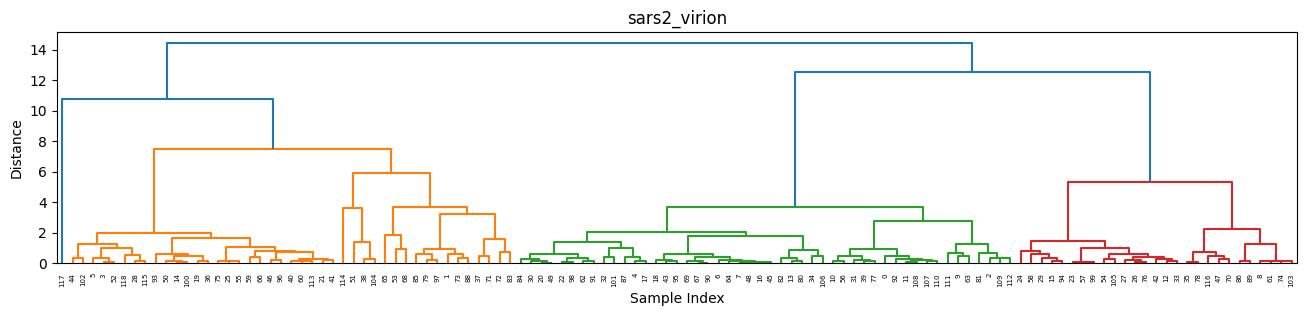

切割距离 = 5.896177727049539
Cluster labels: [4 2 4 1 4 1 4 4 5 4 4 4 5 4 1 5 4 4 4 1 4 1 4 5 5 1 5 5 1 5 4 4 4 5 4 5 1
 2 2 4 1 1 5 4 1 4 1 5 4 4 1 2 1 2 5 1 4 5 5 1 1 5 4 4 4 2 1 4 2 4 5 2 2 2
 5 1 5 4 5 2 4 4 4 2 4 2 5 4 2 5 4 4 4 1 5 4 1 2 4 5 1 4 1 5 2 5 4 4 4 4 4
 4 4 1 2 1 5 3 1]


In [7]:
# sars2_virion
attr1 = sars2_virion_stem_shannon
attr2 = sars2_virion_stem_connection
attr3 = sars2_virion_stem_length

# 将三个列表合并为特征矩阵（每一行代表一个实例）
data = np.array(list(zip(attr1,attr2,attr3)))

# 可选：数据标准化（如果不同属性的量纲差异大时推荐使用）
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# 计算层次聚类（使用标准化后的数据或原始数据）
# 替换为 data 如果不做标准化
Z = linkage(data_scaled, method='ward', metric='euclidean')

# 绘制树状图（帮助确定聚类数量）
fig = plt.figure(figsize=(16, 3))
dendrogram(Z)
plt.title('sars2_virion')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
fig.savefig("sars2_virion_cluster_tree.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 根据树状图结果切割聚类（示例：分成2类）
labels = fcluster(Z, t=5, criterion='maxclust')

cut_distance = Z[-5, 2]   # 第三列就是并类距离
print('切割距离 =', cut_distance)

# 输出每个实例的聚类标签
print("Cluster labels:", labels)

#save_clusters(labels,sars2_virion_structure_locs,'sars2_virion')

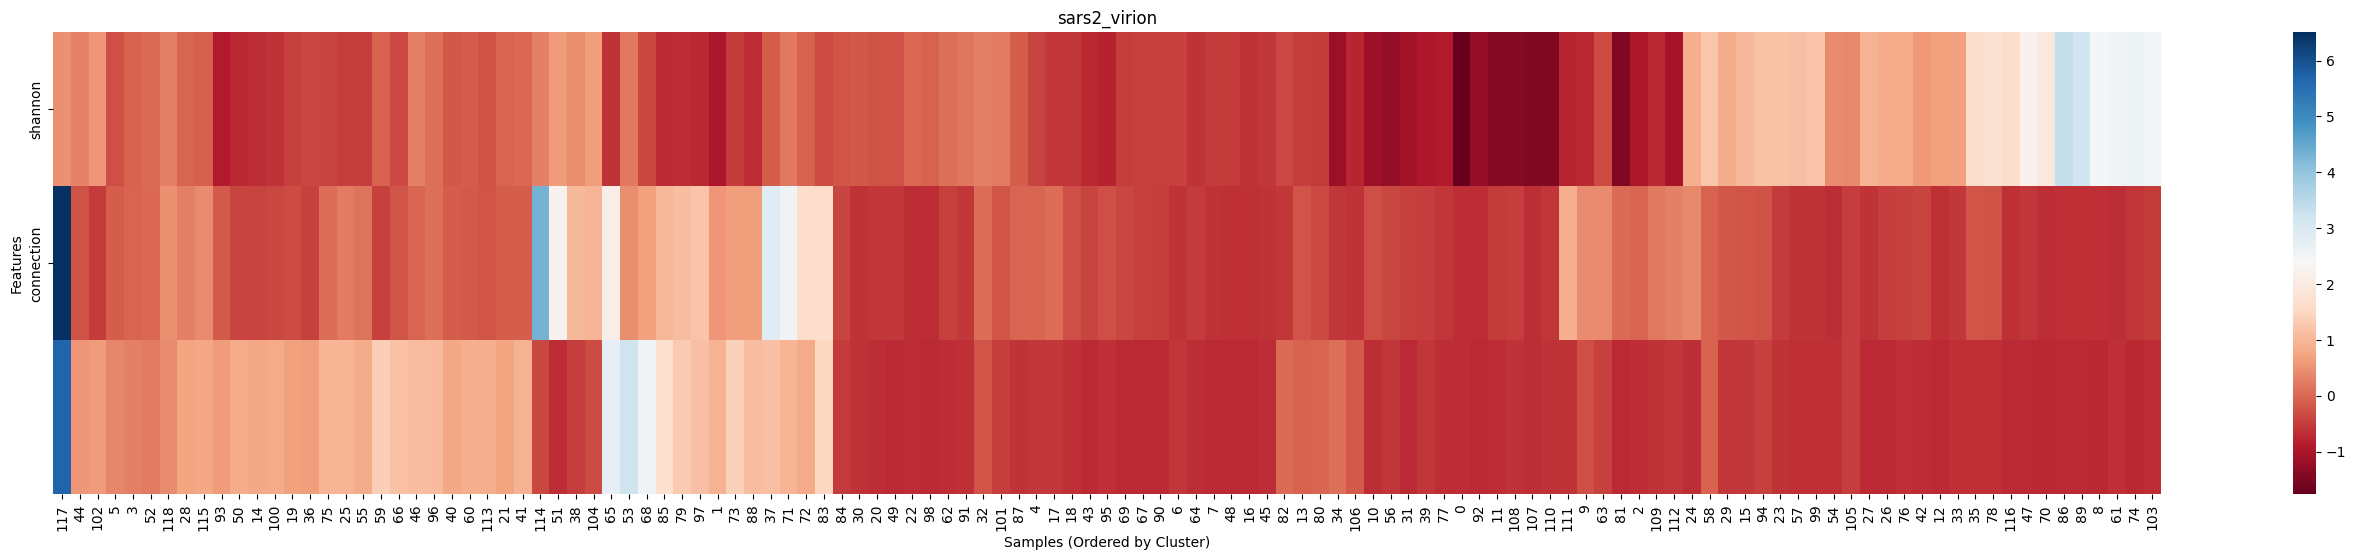

In [27]:
# 获取层次聚类后的行排序索引
dendro_info = dendrogram(Z, no_plot=True)
row_order = dendro_info['leaves']  # 行的排列顺序

# 根据行顺序重新排列数据
sorted_data = data_scaled[row_order]
transposed_sorted_data = sorted_data.T

# 绘制热图
fig = plt.figure(figsize=(34, 6))
sns.heatmap(
    transposed_sorted_data, 
    cmap='RdBu', 
    yticklabels=['shannon', 'connection'],  # 列标签
    xticklabels=row_order                    # 行标签（显示原始索引）
)
plt.title("sars2_virion")
plt.xlabel("Samples (Ordered by Cluster)")
plt.ylabel("Features")
#fig.savefig("sars2_virion_cluster_heatmap.pdf", format='pdf', bbox_inches='tight')
plt.show()

In [25]:
np.unique(labels)

array([1, 2, 3, 4, 5], dtype=int32)

In [26]:
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from sklearn.preprocessing import LabelEncoder
%matplotlib qt

# ---------- 1. 你的数据 ----------
# data_scaled 形状 (119, 3)，已标准化
# labels 长度 119，可以是数字或字符串
X = data_scaled[:, 0]
Y = data_scaled[:, 1]
Z = data_scaled[:, 2]

# ---------- 2. 标签 → 颜色 ----------

total = {
    1:"#FF0101",
    2:"#00FF44",
    3:"#0044FF",
    4:"#FFA600",
    5:"#FF00D9",
}
colors = []
for i,v in enumerate(labels):
    colors.append(total[v])
scalar_map = None

# ---------- 3. 画图 ----------
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(X, Y, Z, c=colors, s=40, edgecolors='k', linewidths=0.2)

# 轴标签
ax.set_xlabel('BPEC (scaled)')
ax.set_ylabel('CS (scaled)')
ax.set_zlabel('Length (scaled)')
#ax.set_title('3D scatter of scaled features')

# 颜色条（仅数值标签）
if scalar_map:
    scalar_map.set_array([])
    fig.colorbar(scalar_map, ax=ax, shrink=0.6, label='label value')

plt.tight_layout()
plt.show()

In [12]:
df = pd.DataFrame({
    'attr1': data_scaled[:, 0],
    'attr2': data_scaled[:, 1],
    'attr3': data_scaled[:, 2],
    'cluster': labels
})

# 对每个属性进行Kruskal-Wallis检验（非参数，不要求正态分布）
results = {}
for attr in ['attr1', 'attr2', 'attr3']:
    groups = [df[df['cluster'] == c][attr].values for c in df['cluster'].unique()]
    h_stat, p_value = stats.kruskal(*groups)
    results[attr] = {'H-statistic': h_stat, 'p-value': p_value}

# H统计量越大，说明该属性在不同聚类间差异越大，贡献越大
print("=== Kruskal-Wallis 检验结果 ===")
for attr, res in results.items():
    print(f"{attr}: H={res['H-statistic']:.2f}, p={res['p-value']:.2e}")

=== Kruskal-Wallis 检验结果 ===
attr1: H=72.81, p=5.78e-15
attr2: H=61.49, p=1.41e-12
attr3: H=77.28, p=6.55e-16


NameError: name 'sars2_virion_shannon_global_median' is not defined

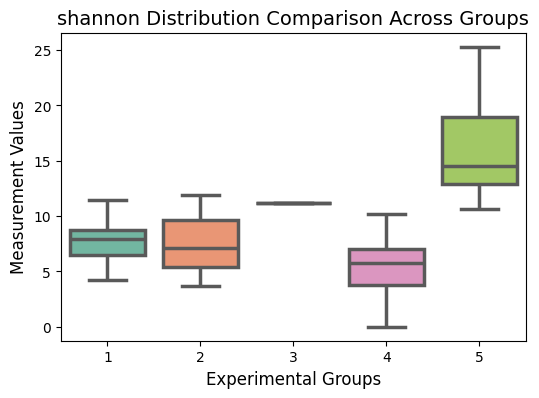

In [ ]:
#attr1 = pdcov_virion_stem_shannon
#attr2 = pdcov_virion_stem_connection
#attr3 = pdcov_virion_stem_length
unique_labels,clusters = separate_cluster(data,labels)

shannon_data = [
    clusters[1][:,0],
    clusters[2][:,0],
    clusters[3][:,0],
    clusters[4][:,0],
    clusters[5][:,0]
]
connection_data = [
    clusters[1][:,1],
    clusters[2][:,1],
    clusters[3][:,1],
    clusters[4][:,1],
    clusters[5][:,1]
]
length_data = [
    clusters[1][:,2],
    clusters[2][:,2],
    clusters[3][:,2],
    clusters[4][:,2],
    clusters[5][:,2]
]

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=shannon_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4','5'])
plt.title("shannon Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_virion_shannon_global_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_virion_shannon.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=connection_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4','5'])
plt.title("connection Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_virion_connection_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_virion_connection.pdf", format='pdf', bbox_inches='tight')
plt.show()

## 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=length_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4','5'])
plt.title("length Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_virion_stem_length_median, color='grey', linestyle='--')
# 显示图形
#fig.savefig("sars2_virion_length.pdf", format='pdf', bbox_inches='tight')
plt.show()

In [17]:
well_folded_labels = [2]
save_well_folded_clusters(well_folded_labels,labels,sars2_virion_structure_locs,'sars2_virion')
save_two_type_well_folded_clusters(well_folded_labels,labels,sars2_virion_structure_locs,'sars2_virion',sars2_virion_stem_shannon,sars2_virion_stem_connection,sars2_virion_shannon_global_median,sars2_virion_connection_median)

In [3]:
sars2_cell_structure = load_pair_bedpe('whole_structure_SARS2_cell_96_v1.bedpe')

SARSCoV2 = 29903

sars2_cell_st_type, sars2_cell_dict_st, sars2_cell_bound = split_structure_bedpe(sars2_cell_structure,SARSCoV2)

In [4]:
sars2_cell_shannon_global = get_shannon(extract_matrix('SARSCoV2_RIC_A549_10_KR.matrix',10),300,10)[1][:SARSCoV2]

sars2_cell_rri_matrix = mask_matrix(extract_oe_matrix('SARSCoV2_RIC_A549_10_KR.matrix',10),300)

sars2_cell_stem_shannon,sars2_cell_stem_connection,sars2_cell_stem_length,sars2_cell_structure_locs = calculate_stem_shannon_connection(sars2_cell_dict_st,sars2_cell_shannon_global,sars2_cell_rri_matrix,'sars2_cell',sars2_cell_structure)

C:\Users\11509\AppData\Local\Temp\ipykernel_2964\2219475574.py:54: RuntimeWarning: invalid value encountered in divide
  p_ma = shannon_ma / shannon_sum


In [5]:
file_path = 'D:/tmp_workplace/dynamic_structure/sars2_partition_5000_3000/'
bp_matrix = create_all_partition_matrixs(file_path,SARSCoV2)

In [6]:
sars2_cell_shannon_global_median = calculate_median_shannon(sars2_cell_shannon_global,bp_matrix,sars2_cell_rri_matrix,SARSCoV2)

sars2_cell_connection_median = calculate_median_connection(sars2_cell_rri_matrix,bp_matrix,SARSCoV2)

sars2_cell_stem_length_median = np.median(sars2_cell_stem_length)

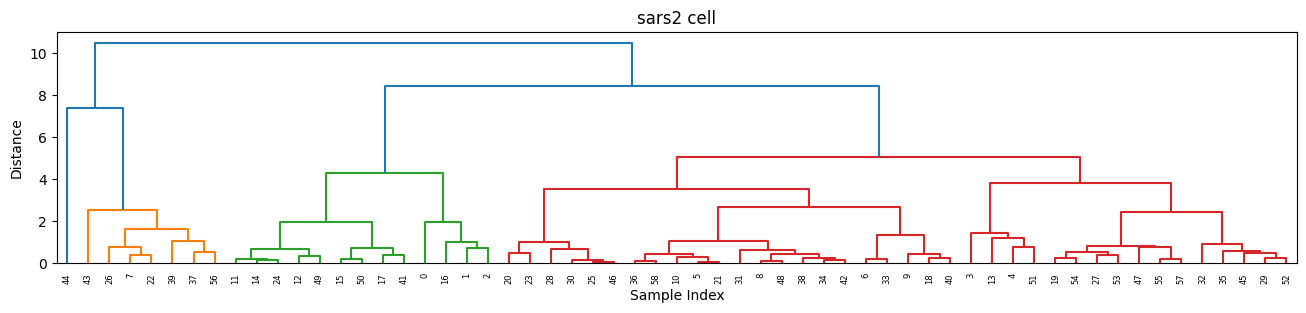

切割距离 = 2.682757917978462
Cluster labels: [4 4 4 7 7 6 6 1 6 6 6 3 3 7 3 3 4 3 6 8 5 6 1 5 3 5 1 8 5 8 5 6 8 6 6 8 6
 1 6 1 6 3 6 1 2 8 5 8 6 3 3 7 8 8 8 8 1 8 6]


In [7]:
# sars2_cell
attr1 = sars2_cell_stem_shannon
attr2 = sars2_cell_stem_connection
attr3 = sars2_cell_stem_length

# 将三个列表合并为特征矩阵（每一行代表一个实例）
data = np.array(list(zip(attr1,attr2,attr3)))

# 可选：数据标准化（如果不同属性的量纲差异大时推荐使用）
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# 计算层次聚类（使用标准化后的数据或原始数据）
# 替换为 data 如果不做标准化
Z = linkage(data_scaled, method='ward', metric='euclidean')

# 绘制树状图（帮助确定聚类数量）
fig = plt.figure(figsize=(16, 3))
dendrogram(Z)
plt.title('sars2 cell')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
fig.savefig("sars2_cell_cluster_tree.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 根据树状图结果切割聚类（示例：分成2类）
labels = fcluster(Z, t=8, criterion='maxclust')

cut_distance = Z[-8, 2]   # 第三列就是并类距离
print('切割距离 =', cut_distance)

# 输出每个实例的聚类标签
print("Cluster labels:", labels)

save_clusters(labels,sars2_cell_structure_locs,'sars2_cell')

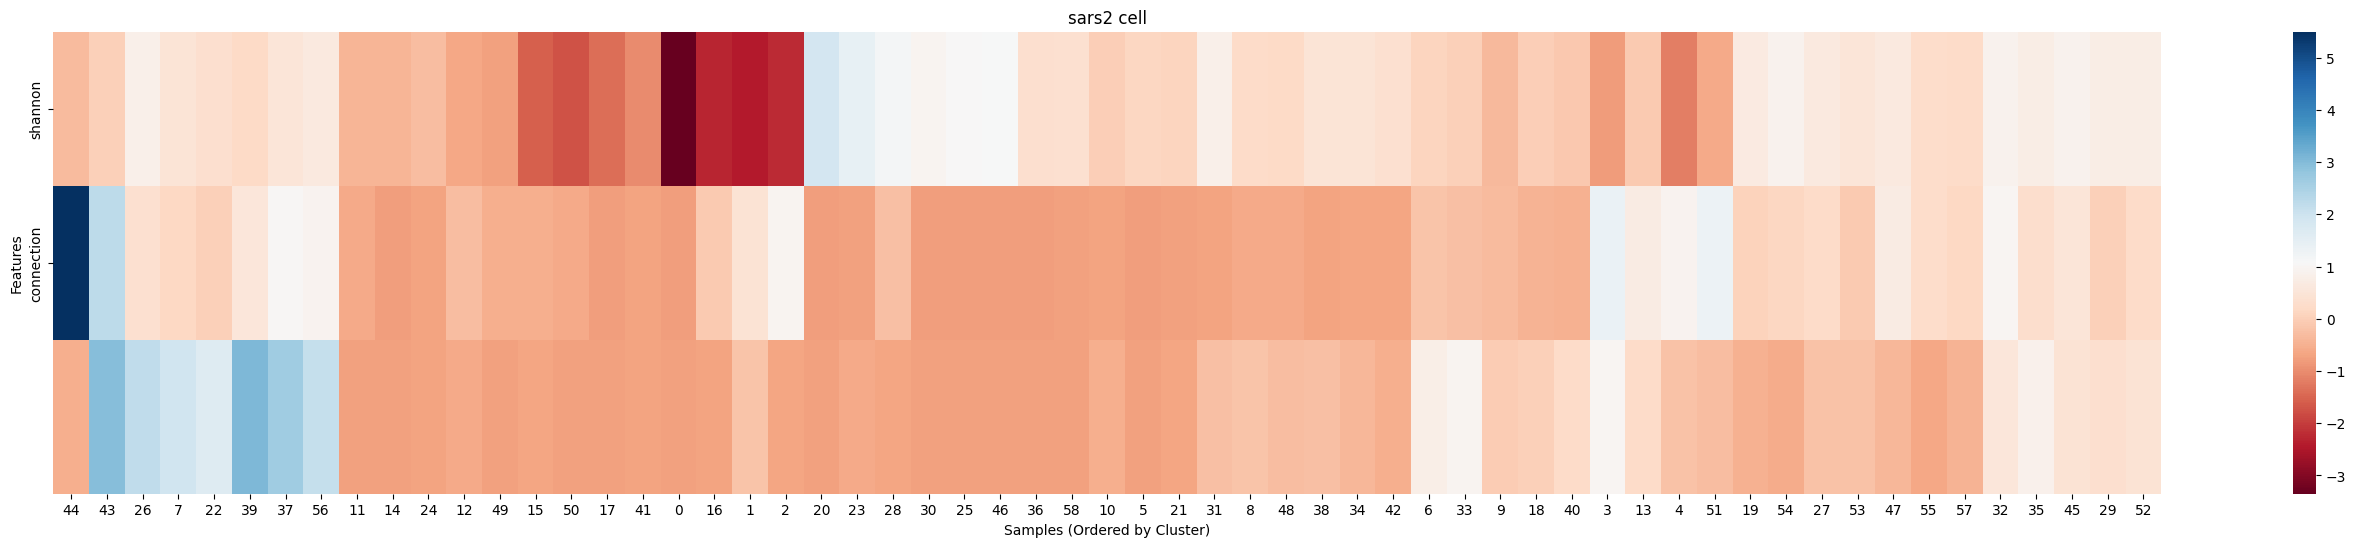

In [8]:
# 获取层次聚类后的行排序索引
dendro_info = dendrogram(Z, no_plot=True)
row_order = dendro_info['leaves']  # 行的排列顺序

# 根据行顺序重新排列数据
sorted_data = data_scaled[row_order]
transposed_sorted_data = sorted_data.T

# 绘制热图
fig = plt.figure(figsize=(34, 6))
sns.heatmap(
    transposed_sorted_data, 
    cmap='RdBu', 
    yticklabels=['shannon', 'connection'],  # 列标签
    xticklabels=row_order                    # 行标签（显示原始索引）
)
plt.title("sars2 cell")
plt.xlabel("Samples (Ordered by Cluster)")
plt.ylabel("Features")
fig.savefig("sars2_cell_cluster_heatmap.pdf", format='pdf', bbox_inches='tight')
plt.show()

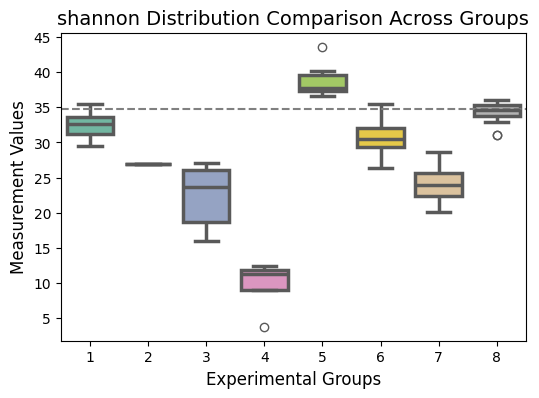

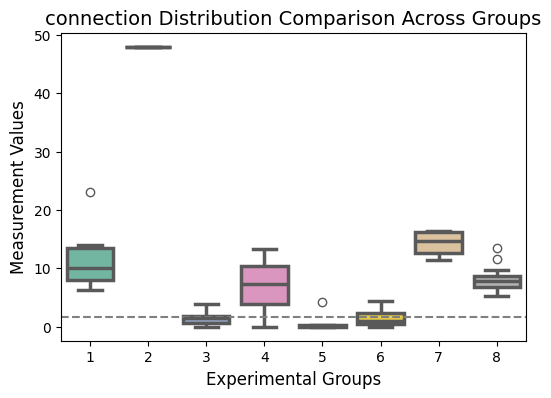

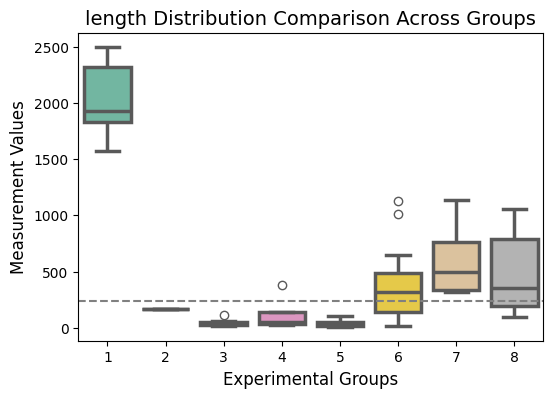

In [9]:
#attr1 = sars2_cell_stem_shannon
#attr2 = sars2_cell_stem_connection
#attr3 = sars2_cell_stem_length
unique_labels,clusters = separate_cluster(data,labels)

shannon_data = [
    clusters[1][:,0],
    clusters[2][:,0],
    clusters[3][:,0],
    clusters[4][:,0],
    clusters[5][:,0],
    clusters[6][:,0],
    clusters[7][:,0],
    clusters[8][:,0]
]
connection_data = [
    clusters[1][:,1],
    clusters[2][:,1],
    clusters[3][:,1],
    clusters[4][:,1],
    clusters[5][:,1],
    clusters[6][:,1],
    clusters[7][:,1],
    clusters[8][:,1]
]
length_data = [
    clusters[1][:,2],
    clusters[2][:,2],
    clusters[3][:,2],
    clusters[4][:,2],
    clusters[5][:,2],
    clusters[6][:,2],
    clusters[7][:,2],
    clusters[8][:,2]
]

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=shannon_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4','5','6','7','8'])
plt.title("shannon Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_cell_shannon_global_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_cell_shannon.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=connection_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4','5','6','7','8'])
plt.title("connection Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_cell_connection_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_cell_connection.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=length_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4','5','6','7','8'])
plt.title("length Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_cell_stem_length_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_cell_length.pdf", format='pdf', bbox_inches='tight')
plt.show()

In [10]:
well_folded_labels = [1,2,4,7]
save_well_folded_clusters(well_folded_labels,labels,sars2_cell_structure_locs,'sars2_cell')
save_two_type_well_folded_clusters(well_folded_labels,labels,sars2_cell_structure_locs,'sars2_cell',sars2_cell_stem_shannon,sars2_cell_stem_connection,sars2_cell_shannon_global_median,sars2_cell_connection_median)

In [13]:
sars2_vero_structure = load_pair_bedpe('whole_structure_SARS2_vero_96_v1.bedpe')

SARSCoV2 = 29903

sars2_vero_st_type, sars2_vero_dict_st, sars2_vero_bound = split_structure_bedpe(sars2_vero_structure,SARSCoV2)

In [14]:
sars2_vero_shannon_global = get_shannon(extract_matrix('SARSCoV2_VERO_RIC_merge_10_KR.matrix',10),300,10)[1][:SARSCoV2]

sars2_vero_rri_matrix = mask_matrix(extract_oe_matrix('SARSCoV2_VERO_RIC_merge_10_KR.matrix',10),300)

sars2_vero_stem_shannon,sars2_vero_stem_connection,sars2_vero_stem_length,sars2_vero_structure_locs = calculate_stem_shannon_connection(sars2_vero_dict_st,sars2_vero_shannon_global,sars2_vero_rri_matrix,'sars2_vero',sars2_vero_structure)

C:\Users\11509\AppData\Local\Temp\ipykernel_21736\2219475574.py:54: RuntimeWarning: invalid value encountered in divide
  p_ma = shannon_ma / shannon_sum


In [5]:
file_path = 'D:/tmp_workplace/dynamic_structure/sars2_partition_5000_3000/'
bp_matrix = create_all_partition_matrixs(file_path,SARSCoV2)

In [15]:
sars2_vero_shannon_global_median = calculate_median_shannon(sars2_vero_shannon_global,bp_matrix,sars2_vero_rri_matrix,SARSCoV2)

sars2_vero_connection_median = calculate_median_connection(sars2_vero_rri_matrix,bp_matrix,SARSCoV2)

sars2_vero_stem_length_median = np.median(sars2_vero_stem_length)

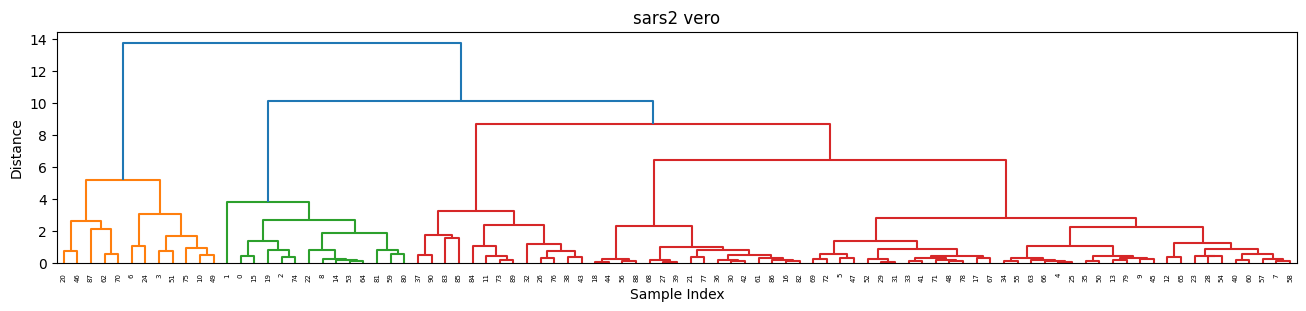

切割距离 = 6.442649381381235
Cluster labels: [2 2 2 1 4 4 1 4 2 4 1 3 4 4 2 2 4 4 4 2 1 4 2 4 1 4 3 4 4 4 4 4 3 4 4 4 4
 3 3 4 4 4 4 3 4 4 1 4 4 1 4 1 4 2 4 4 4 4 4 2 4 4 1 4 2 4 4 4 4 4 1 4 4 3
 2 1 3 4 4 4 2 2 4 3 3 3 4 1 4 3 3]


In [16]:
# sars2_vero
attr1 = sars2_vero_stem_shannon
attr2 = sars2_vero_stem_connection
attr3 = sars2_vero_stem_length

# 将三个列表合并为特征矩阵（每一行代表一个实例）
data = np.array(list(zip(attr1, attr2, attr3)))

# 可选：数据标准化（如果不同属性的量纲差异大时推荐使用）
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# 计算层次聚类（使用标准化后的数据或原始数据）
# 替换为 data 如果不做标准化
Z = linkage(data_scaled, method='ward', metric='euclidean')

# 绘制树状图（帮助确定聚类数量）
fig = plt.figure(figsize=(16, 3))
dendrogram(Z)
plt.title('sars2 vero')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
fig.savefig("sars2_vero_cluster_tree.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 根据树状图结果切割聚类（示例：分成2类）
labels = fcluster(Z, t=4, criterion='maxclust')

cut_distance = Z[-4, 2]   # 第三列就是并类距离
print('切割距离 =', cut_distance)

# 输出每个实例的聚类标签
print("Cluster labels:", labels)

save_clusters(labels,sars2_vero_structure_locs,'sars2_vero')

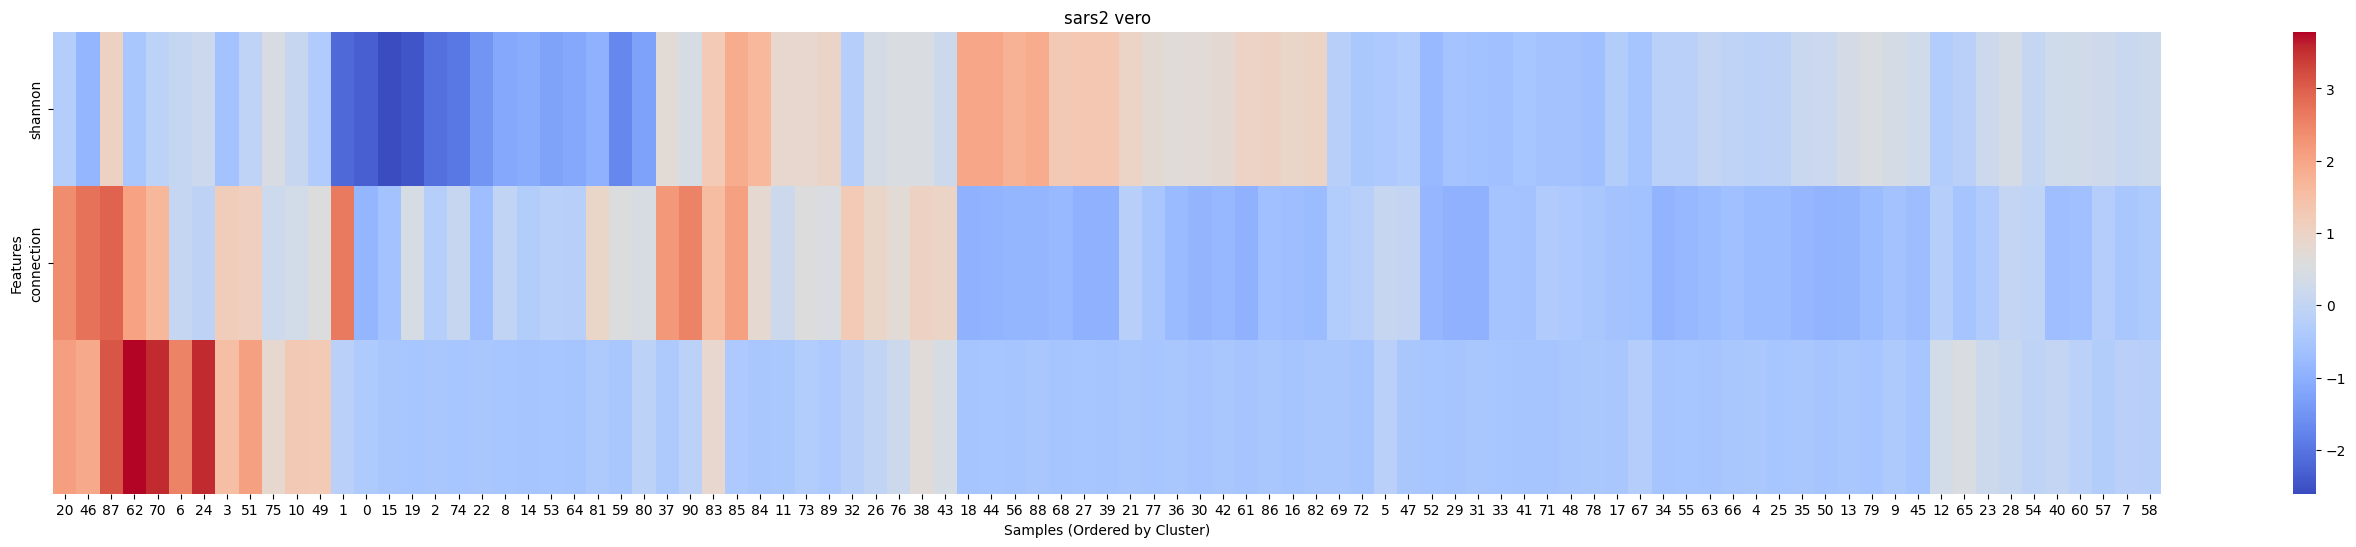

In [20]:
# 获取层次聚类后的行排序索引
dendro_info = dendrogram(Z, no_plot=True)
row_order = dendro_info['leaves']  # 行的排列顺序

# 根据行顺序重新排列数据
sorted_data = data_scaled[row_order]
transposed_sorted_data = sorted_data.T

# 绘制热图
fig = plt.figure(figsize=(34, 6))
sns.heatmap(
    transposed_sorted_data, 
    cmap='coolwarm', 
    yticklabels=['shannon', 'connection'],  # 列标签
    xticklabels=row_order                    # 行标签（显示原始索引）
)
plt.title("sars2 vero")
plt.xlabel("Samples (Ordered by Cluster)")
plt.ylabel("Features")
fig.savefig("sars2_vero_cluster_heatmap.pdf", format='pdf', bbox_inches='tight')
plt.show()

In [31]:
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from sklearn.preprocessing import LabelEncoder
%matplotlib qt

# ---------- 1. 你的数据 ----------
# data_scaled 形状 (119, 3)，已标准化
# labels 长度 119，可以是数字或字符串
X = data_scaled[:, 0]
Y = data_scaled[:, 1]
Z = data_scaled[:, 2]

# ---------- 2. 标签 → 颜色 ----------

total = {
    1:"#FF0101",
    2:"#00FF44",
    3:"#0044FF",
    4:"#FFA600"
}
colors = []
for i,v in enumerate(labels):
    colors.append(total[v])
scalar_map = None

# ---------- 3. 画图 ----------
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(X, Y, Z, c=colors, s=40, edgecolors='k', linewidths=0.2)

# 轴标签
ax.set_xlabel('BPEC (scaled)')
ax.set_ylabel('CS (scaled)')
ax.set_zlabel('Length (scaled)')
#ax.set_title('3D scatter of scaled features')

# 颜色条（仅数值标签）
if scalar_map:
    scalar_map.set_array([])
    fig.colorbar(scalar_map, ax=ax, shrink=0.6, label='label value')

plt.tight_layout()
plt.show()

In [17]:
df = pd.DataFrame({
    'attr1': data_scaled[:, 0],
    'attr2': data_scaled[:, 1],
    'attr3': data_scaled[:, 2],
    'cluster': labels
})

# 对每个属性进行Kruskal-Wallis检验（非参数，不要求正态分布）
results = {}
for attr in ['attr1', 'attr2', 'attr3']:
    groups = [df[df['cluster'] == c][attr].values for c in df['cluster'].unique()]
    h_stat, p_value = stats.kruskal(*groups)
    results[attr] = {'H-statistic': h_stat, 'p-value': p_value}

# H统计量越大，说明该属性在不同聚类间差异越大，贡献越大
print("=== Kruskal-Wallis 检验结果 ===")
for attr, res in results.items():
    print(f"{attr}: H={res['H-statistic']:.2f}, p={res['p-value']:.2e}")

=== Kruskal-Wallis 检验结果 ===
attr1: H=42.24, p=3.57e-09
attr2: H=57.34, p=2.18e-12
attr3: H=42.04, p=3.93e-09


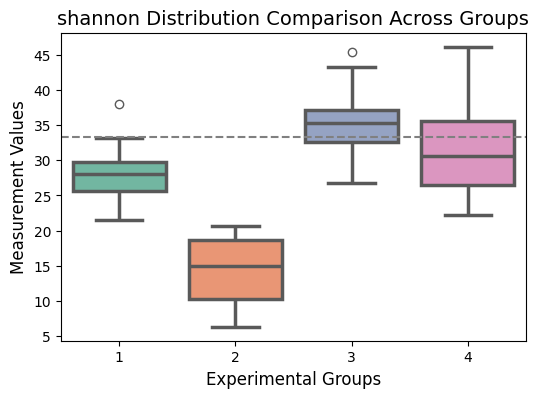

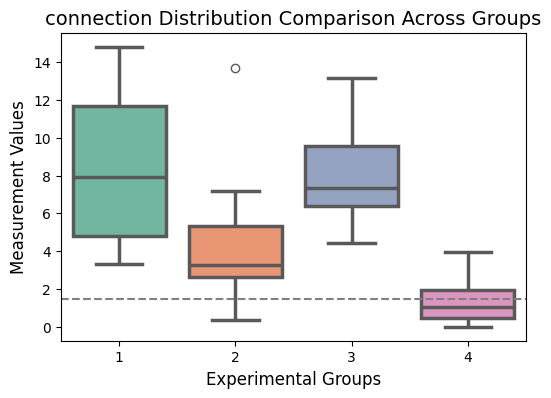

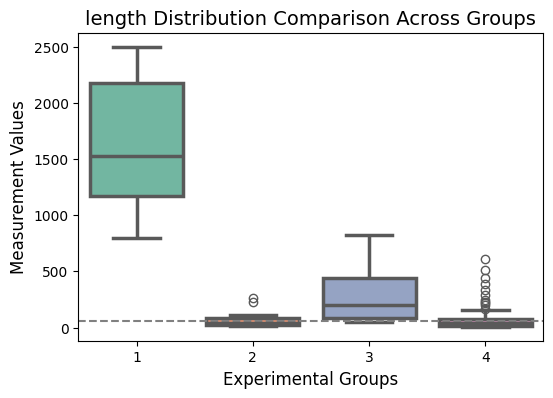

In [9]:
#attr1 = sars2_cell_stem_shannon
#attr2 = sars2_cell_stem_connection
#attr3 = sars2_cell_stem_length
unique_labels,clusters = separate_cluster(data,labels)

shannon_data = [
    clusters[1][:,0],
    clusters[2][:,0],
    clusters[3][:,0],
    clusters[4][:,0]
]
connection_data = [
    clusters[1][:,1],
    clusters[2][:,1],
    clusters[3][:,1],
    clusters[4][:,1]
]
length_data = [
    clusters[1][:,2],
    clusters[2][:,2],
    clusters[3][:,2],
    clusters[4][:,2]
]

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=shannon_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4'])
plt.title("shannon Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_vero_shannon_global_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_vero_shannon.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=connection_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4'])
plt.title("connection Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_vero_connection_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_vero_connection.pdf", format='pdf', bbox_inches='tight')
plt.show()

# 绘制箱线图
fig = plt.figure(figsize=(6, 4))
sns.boxplot(
    data=length_data, 
    palette="Set2",  # 颜色方案
    linewidth=2.5    # 箱线边框粗细
)
# 添加标题和标签
plt.xticks(ticks=range(len(unique_labels)), labels=['1','2','3','4'])
plt.title("length Distribution Comparison Across Groups", fontsize=14)
plt.xlabel("Experimental Groups", fontsize=12)
plt.ylabel("Measurement Values", fontsize=12)
plt.axhline(sars2_vero_stem_length_median, color='grey', linestyle='--')
# 显示图形
fig.savefig("sars2_vero_length.pdf", format='pdf', bbox_inches='tight')
plt.show()

In [10]:
well_folded_labels = [1,2]
save_well_folded_clusters(well_folded_labels,labels,sars2_vero_structure_locs,'sars2_vero')
save_two_type_well_folded_clusters(well_folded_labels,labels,sars2_vero_structure_locs,'sars2_vero',sars2_vero_stem_shannon,sars2_vero_stem_connection,sars2_vero_shannon_global_median,sars2_vero_connection_median)